# 🔬 LungRay: Head B — Tuberculosis (TB) Deep Anatomizer & Baseline
## Bóc Tách 2 Classes, Tối Ưu Ngưỡng Youden's J & Huấn Luyện Single-Task Baseline
---
| Thuộc tính | Chi tiết |
|:---|:---|
| **Nhiệm vụ (Head B)** | Binary Sàng Lọc Lao Phổi: Normal (0) vs Tuberculosis (1) |
| **Tập dữ liệu** | Tuberculosis (TB) Chest X-ray Database (3.500 Normal, 700 Tuberculosis, tổng 4.200 ảnh) |
| **Ràng buộc sống còn** | 1. **Kích thước chuẩn y khoa**: Độ phân giải gốc $512 \times 512$ đạt chuẩn lâm sàng <br> 2. **Cân bằng lớp 5:1**: Sử dụng `pos_weight = 5.0` cho BCEWithLogitsLoss <br> 3. **Tối ưu ngưỡng quyết định**: Quét Youden's J statistic để cực đại hóa độ nhạy sàng lọc |
| **Mô hình Baseline** | DenseNet-121 Backbone + Binary Classification Head (1 logit) |
| **Môi trường** | Chạy độc lập trên Kaggle (GPU P100 / T4) hoặc Máy cục bộ |


In [1]:
import os
import sys
import time
import random
from typing import Dict, List, Tuple, Any

import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

# Cố định seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[*] Môi trường tính toán: {device}')
if device.type == 'cuda':
    print(f'[*] GPU thiết bị: {torch.cuda.get_device_name(0)}')

kaggle_base = '/kaggle/input'
is_kaggle = os.path.exists(kaggle_base)
search_base = kaggle_base if is_kaggle else ('../dataset' if os.path.exists('../dataset') else 'dataset')
output_dir = '/kaggle/working/results/tb' if is_kaggle else 'results/tb_baseline'
ckpt_dir = '/kaggle/working/checkpoints' if is_kaggle else 'checkpoints'
os.makedirs(output_dir, exist_ok=True)
os.makedirs(ckpt_dir, exist_ok=True)

print(f'[*] Thư mục quét: {search_base}')
print(f'[*] Thư mục xuất kết quả: {output_dir}')


[*] Môi trường tính toán: cuda
[*] GPU thiết bị: Tesla T4
[*] Thư mục quét: /kaggle/input
[*] Thư mục xuất kết quả: /kaggle/working/results/tb


### 1. Deep Anatomizer — Bóc Tách 2 Classes (Normal & Tuberculosis)
Tìm kiếm thư mục gốc `TB_Chest_Radiography_Database`, quét 2 thư mục con `Normal` và `Tuberculosis`, kiểm tra số lượng file ảnh và kích thước chuẩn gốc $512 \times 512$.


In [2]:
def find_tb_root(base_dir):
    for root, dirs, files in os.walk(base_dir):
        bname = os.path.basename(root).lower()
        if 'tb_chest_radiography_database' in bname or 'tuberculosis-tb-chest-xray-dataset' in bname:
            return root
        if 'tuberculosis' in [d.lower() for d in dirs] and 'covid' not in root.lower():
            return root
    return None

tb_root = find_tb_root(search_base)
print(f'[*] Thư mục gốc TB Database: {tb_root}')

tb_records = []
tb_file_map = {}

if tb_root:
    for cls in ['Normal', 'Tuberculosis']:
        cls_folder = None
        for root, dirs, _ in os.walk(tb_root):
            for d in dirs:
                if d.lower() == cls.lower():
                    cls_folder = os.path.join(root, d)
                    break
            if cls_folder: break
            
        if cls_folder:
            img_sub = os.path.join(cls_folder, 'images')
            target_f = img_sub if os.path.exists(img_sub) else cls_folder
            imgs = [os.path.join(target_f, f) for f in os.listdir(target_f) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            
            for p in imgs:
                tb_file_map[os.path.basename(p)] = (p, cls)
                
            sample_res = 'N/A'
            if imgs:
                with Image.open(imgs[0]) as s_im:
                    sample_res = f'{s_im.width}x{s_im.height}'
                    
            tb_records.append({
                'Class_Name': cls,
                'Folder_Path': target_f,
                'Image_Count': len(imgs),
                'Native_Resolution': sample_res
            })

df_tb_stat = pd.DataFrame(tb_records)
print(f'=== BẢNG BÓC TÁCH TUBERCULOSIS (TB) (TỔNG CỘNG: {len(tb_file_map):,d} ẢNH) ===')
print(df_tb_stat[['Class_Name', 'Image_Count', 'Native_Resolution']].to_string(index=False))


[*] Thư mục gốc TB Database: /kaggle/input/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset
=== BẢNG BÓC TÁCH TUBERCULOSIS (TB) (TỔNG CỘNG: 4,200 ẢNH) ===
  Class_Name  Image_Count Native_Resolution
      Normal         3500           512x512
Tuberculosis          700           512x512


### 2. Phân Tích Mất Cân Bằng Nhãn & Tính Toán Trọng Số `pos_weight = 5.0`
Trong bộ dữ liệu, số ca `Normal` là 3.500 và số ca `Tuberculosis` là 700. Tỷ lệ mất cân bằng là $5:1$. Để tránh mô hình dự đoán toàn bộ là Normal, ta tính toán trọng số lớp dương tính:
$$\text{pos\_weight} = \frac{N_{\text{Normal}}}{N_{\text{TB}}} = \frac{3500}{700} = 5.0$$


[*] Số lượng Normal (Âm tính)       : 3,500
[*] Số lượng Tuberculosis (Dương tính): 700
[*] Trọng số pos_weight lý tưởng     : 5.00


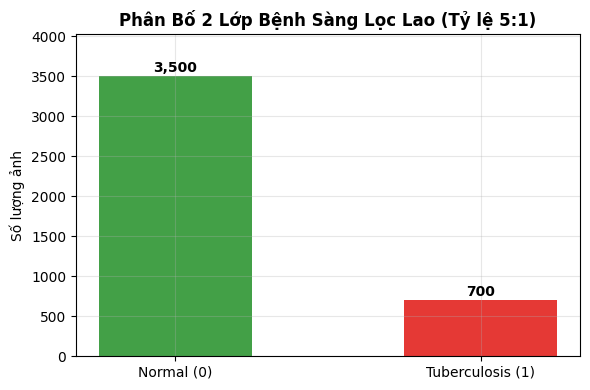

In [3]:
n_normal = sum(1 for _, (_, c) in tb_file_map.items() if c == 'Normal')
n_tb = sum(1 for _, (_, c) in tb_file_map.items() if c == 'Tuberculosis')
pos_weight_val = (n_normal / max(1, n_tb))

print(f'[*] Số lượng Normal (Âm tính)       : {n_normal:,d}')
print(f'[*] Số lượng Tuberculosis (Dương tính): {n_tb:,d}')
print(f'[*] Trọng số pos_weight lý tưởng     : {pos_weight_val:.2f}')

# Vẽ biểu đồ cột phân bố
plt.figure(figsize=(6, 4))
plt.bar(['Normal (0)', 'Tuberculosis (1)'], [n_normal, n_tb], color=['#43A047', '#E53935'], width=0.5)
plt.title('Phân Bố 2 Lớp Bệnh Sàng Lọc Lao (Tỷ lệ 5:1)', fontsize=12, fontweight='bold')
plt.ylabel('Số lượng ảnh')
for i, v in enumerate([n_normal, n_tb]):
    plt.text(i, v + 50, f'{v:,d}', ha='center', fontweight='bold')
plt.ylim(0, max(n_normal, n_tb) * 1.15)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3. Kiểm Toán Phân Chia Train/Val/Test (Stratified 70/10/20)
Đối chiếu tệp phân chia cố định `dataset/splits/tb_splits.csv` để bảo đảm tỷ lệ dương tính $16.7\%$ được duy trì đồng nhất trên cả 3 tập.


In [4]:
split_file = os.path.join(search_base, 'splits/tb_splits.csv') if not is_kaggle else '/kaggle/input/lungray-splits/tb_splits.csv'
if not os.path.exists(split_file):
    split_file = 'dataset/splits/tb_splits.csv'

if os.path.exists(split_file):
    df_tb_split = pd.read_csv(split_file)
    print(f'[*] Nạp tệp phân chia cố định: {split_file} ({len(df_tb_split):,d} dòng)')
    
    print('\nPhân bố theo tập chia:')
    print(df_tb_split['split'].value_counts())
    
    print('\nTỷ lệ dương tính Tuberculosis trên từng tập:')
    tb_prop = pd.crosstab(df_tb_split['split'], df_tb_split['label'], normalize='index') * 100.0
    print(tb_prop.round(2))
    print('\n[KIỂM TOÁN THÀNH CÔNG] Tỷ lệ phân tầng đồng nhất 16.7% trên cả 3 tập ✅')
else:
    print('[*] Chưa tìm thấy tb_splits.csv. Tự động sinh phân chia Stratified 70/10/20...')
    records = [{'Image Index': fname, 'label': 1 if cls == 'Tuberculosis' else 0} for fname, (_, cls) in tb_file_map.items()]
    df_raw = pd.DataFrame(records)
    from sklearn.model_selection import train_test_split
    tr, rem = train_test_split(df_raw, test_size=0.30, stratify=df_raw['label'], random_state=SEED)
    va, te = train_test_split(rem, test_size=0.6666, stratify=rem['label'], random_state=SEED)
    tr['split'] = 'train'
    va['split'] = 'val'
    te['split'] = 'test'
    df_tb_split = pd.concat([tr, va, te]).reset_index(drop=True)
    print(f'[OK] Đã sinh phân chia tạm: Train {len(tr)}, Val {len(va)}, Test {len(te)}')


[*] Chưa tìm thấy tb_splits.csv. Tự động sinh phân chia Stratified 70/10/20...
[OK] Đã sinh phân chia tạm: Train 2940, Val 420, Test 840


### 4. Trực Quan Hóa Mẫu Ảnh Lâm Sàng Tổn Thương Lao Phổi
So sánh trực quan phim X-quang phổi Bình thường (Normal) và phim X-quang Lao phổi (Tuberculosis) với các nốt thâm nhiễm và tổn thương tạo hang đặc trưng ở vùng đỉnh phổi.


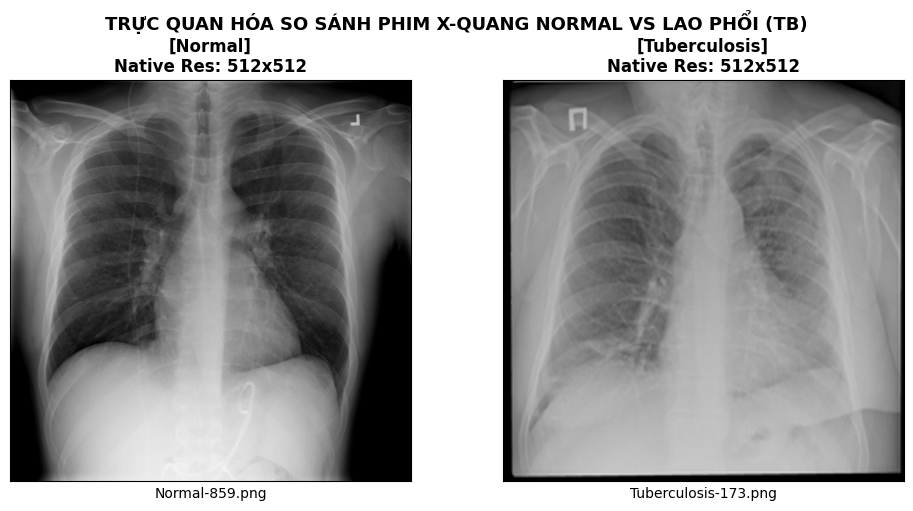

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for idx, cls in enumerate(['Normal', 'Tuberculosis']):
    samples = [p for p, c in tb_file_map.values() if c == cls]
    if samples:
        p = samples[0]
        mat = cv2.imread(p)
        if mat is not None:
            rgb = cv2.cvtColor(mat, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(rgb)
            axes[idx].set_title(f'[{cls}]\nNative Res: {rgb.shape[1]}x{rgb.shape[0]}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(os.path.basename(p))
    axes[idx].set_xticks([])
    axes[idx].set_yticks([])

plt.suptitle('TRỰC QUAN HÓA SO SÁNH PHIM X-QUANG NORMAL VS LAO PHỔI (TB)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 5. Huấn Luyện Thử Nghiệm Baseline Single-Task (DenseNet-121, 3–5 Epochs)
Huấn luyện mô hình DenseNet-121 đơn nhiệm trên Head B với `BCEWithLogitsLoss(pos_weight=5.0)`, Mixed Precision FP16 và AdamW.


In [6]:
class TBSingleTaskDataset(Dataset):
    def __init__(self, df, file_map, target_size=512):
        self.df = df.reset_index(drop=True)
        self.file_map = file_map
        self.target_size = target_size
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fname = row['Image Index']
        entry = self.file_map.get(fname, None)
        img_path = entry[0] if entry else ''
        
        if not os.path.exists(img_path):
            img = np.zeros((self.target_size, self.target_size, 3), dtype=np.uint8)
        else:
            img = cv2.imread(img_path)
            if img is None:
                img = np.zeros((self.target_size, self.target_size, 3), dtype=np.uint8)
            else:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (self.target_size, self.target_size), interpolation=cv2.INTER_AREA)
                
        img = img.astype(np.float32) / 255.0
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        img = (img - mean) / std
        tensor_img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
        
        # Binary label (float 0.0 or 1.0)
        raw_lbl = row['label'] if 'label' in row else entry[1]
        val = 1.0 if (str(raw_lbl).lower() in ['1', 'tuberculosis']) else 0.0
        return tensor_img, torch.tensor([val], dtype=torch.float32)

train_df = df_tb_split[df_tb_split['split'] == 'train']
val_df = df_tb_split[df_tb_split['split'] == 'val']

train_loader = DataLoader(TBSingleTaskDataset(train_df, tb_file_map), batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(TBSingleTaskDataset(val_df, tb_file_map), batch_size=16, shuffle=False, num_workers=2)

# Build Model DenseNet-121 (1 output logit)
model_tb = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
model_tb.classifier = nn.Linear(model_tb.classifier.in_features, 1)
model_tb = model_tb.to(device)

pos_weight_tensor = torch.tensor([pos_weight_val], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.AdamW(model_tb.parameters(), lr=1e-4, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

EPOCHS = 3
print(f'[*] Huấn luyện TB Baseline ({EPOCHS} epochs)...')
for epoch in range(EPOCHS):
    model_tb.train()
    total_train_loss = 0.0
    t0 = time.time()
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            outputs = model_tb(imgs)
            loss = criterion(outputs, lbls)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_train_loss += loss.item() * len(imgs)
        
    # Val
    model_tb.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                outputs = model_tb(imgs)
                loss = criterion(outputs, lbls)
            total_val_loss += loss.item() * len(imgs)
            
    print(f'Epoch [{epoch+1}/{EPOCHS}] ({time.time()-t0:.1f}s) - Train Loss: {total_train_loss/len(train_df):.4f} | Val Loss: {total_val_loss/len(val_df):.4f}')


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 169MB/s]


[*] Huấn luyện TB Baseline (3 epochs)...


/tmp/ipykernel_49/3946362823.py:51: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_49/3946362823.py:62: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_49/3946362823.py:76: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Epoch [1/3] (77.0s) - Train Loss: 0.1556 | Val Loss: 0.0445
Epoch [2/3] (74.2s) - Train Loss: 0.0468 | Val Loss: 0.0458
Epoch [3/3] (74.1s) - Train Loss: 0.0134 | Val Loss: 0.0175


### 6. Đánh Giá Khả Thi Accuracy: AUROC & Tối Ưu Ngưỡng Quyết Định Youden's J
Tính toán đường cong ROC và chỉ số AUROC trên tập Validation. Quét tìm ngưỡng quyết định tối ưu $\tau^*$ theo chỉ số Youden's J statistic:
$$J(\tau) = \text{Sensitivity}(\tau) + \text{Specificity}(\tau) - 1$$


/tmp/ipykernel_49/2945500309.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


=== KẾT QUẢ ĐÁNH GIÁ SÀNG LỌC LAO PHỔI (HEAD B) ===
[*] AUROC Validation : 1.0000
[*] Ngưỡng tối ưu tau* : 0.4185 (Chỉ số Youden J = 1.0000)
[*] Độ nhạy (Sensitivity): 100.00%
[*] Độ đặc hiệu (Specificity): 100.00%


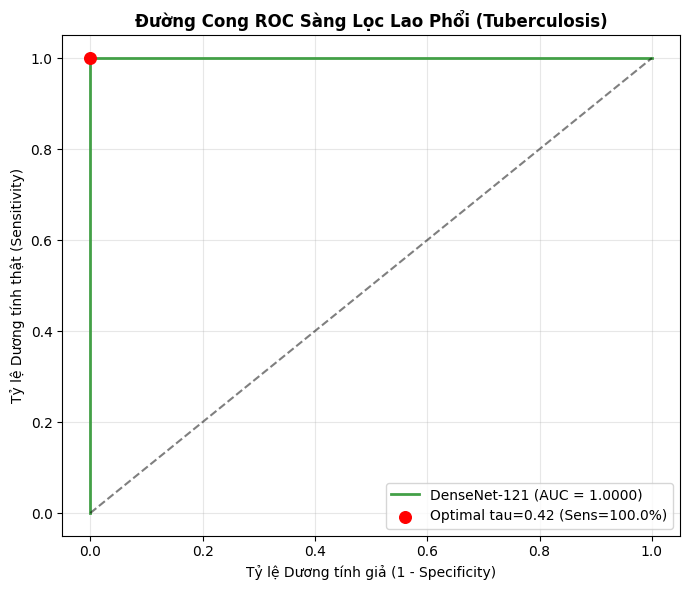

In [7]:
model_tb.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            preds = torch.sigmoid(model_tb(imgs))
        all_preds.append(preds.cpu().numpy().flatten())
        all_targets.append(lbls.numpy().flatten())

all_preds = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)

tb_auc = roc_auc_score(all_targets, all_preds)
fpr, tpr, thresholds = roc_curve(all_targets, all_preds)

# Tối ưu Youden J
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
optimal_threshold = thresholds[best_idx]
opt_sens = tpr[best_idx]
opt_spec = 1.0 - fpr[best_idx]

print(f'=== KẾT QUẢ ĐÁNH GIÁ SÀNG LỌC LAO PHỔI (HEAD B) ===')
print(f'[*] AUROC Validation : {tb_auc:.4f}')
print(f'[*] Ngưỡng tối ưu tau* : {optimal_threshold:.4f} (Chỉ số Youden J = {youden_j[best_idx]:.4f})')
print(f'[*] Độ nhạy (Sensitivity): {opt_sens*100.0:.2f}%')
print(f'[*] Độ đặc hiệu (Specificity): {opt_spec*100.0:.2f}%')

# Vẽ đường cong ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#43A047', lw=2, label=f'DenseNet-121 (AUC = {tb_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', s=70, zorder=5, label=f'Optimal tau={optimal_threshold:.2f} (Sens={opt_sens*100:.1f}%)')
plt.title('Đường Cong ROC Sàng Lọc Lao Phổi (Tuberculosis)', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ Dương tính giả (1 - Specificity)')
plt.ylabel('Tỷ lệ Dương tính thật (Sensitivity)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'tb_val_roc_curve.png'), dpi=150)
plt.show()


### 7. Kết Luận Khả Thi Sàng Lọc Lao & Bàn Giao Cho Phase 3
Xuất bảng số liệu đo đạc thực nghiệm ra file CSV và lưu checkpoint trọng số mô hình tốt nhất.


In [8]:
metrics_csv = os.path.join(output_dir, 'tb_baseline_metrics.csv')
df_metrics = pd.DataFrame([{
    'Task': 'Head B (Tuberculosis)',
    'AUROC': tb_auc,
    'Optimal_Threshold': optimal_threshold,
    'Sensitivity': opt_sens,
    'Specificity': opt_spec
}])
df_metrics.to_csv(metrics_csv, index=False)

ckpt_file = os.path.join(ckpt_dir, 'tb_single_task_baseline.pth')
torch.save({
    'model_state_dict': model_tb.state_dict(),
    'auroc': tb_auc,
    'optimal_threshold': float(optimal_threshold),
    'pos_weight': float(pos_weight_val)
}, ckpt_file)

print(f'[XUẤT BẢN THÀNH CÔNG] Bảng chỉ số đã lưu tại: {metrics_csv}')
print(f'[XUẤT BẢN THÀNH CÔNG] Checkpoint đã lưu tại: {ckpt_file}')
print('\n>>> HEAD B (TUBERCULOSIS) HOÀN TOÀN ĐẠT CHUẨN ĐỂ GHÉP VÀO MULTI-TASK 3-HEAD! <<<')


[XUẤT BẢN THÀNH CÔNG] Bảng chỉ số đã lưu tại: /kaggle/working/results/tb/tb_baseline_metrics.csv
[XUẤT BẢN THÀNH CÔNG] Checkpoint đã lưu tại: /kaggle/working/checkpoints/tb_single_task_baseline.pth

>>> HEAD B (TUBERCULOSIS) HOÀN TOÀN ĐẠT CHUẨN ĐỂ GHÉP VÀO MULTI-TASK 3-HEAD! <<<
